# Optimal to operate: random ESC parameters on random drifting plants (10k runs)

**Question.** How do the ESC parameters affect the energy produced, and when does ESC give more energy than
keeping the fuel ratio fixed at $r = 0.5$?

**Data.** `OTO-ESC-10k.csv`, generated by `OTO_ESC_rand_Plant_rand.m`: 10,000 runs of 100 s. Each run draws
random ESC parameters (as in the safe-to-operate sweeps) and a random plant with
$r_{\mathrm{ideal},0} \in [0.45, 0.55]$ and $\lambda \in [-0.002, 0.002]$ s$^{-1}$. The estimate $\hat r$ starts at 0.5.

## 1. Setup

In [1]:
# Shared tools (plot style, model constants, averaged-ESC formulas) live in Tools/ at the repository root
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'Tools' / 'esc_tools.py').exists())
sys.path.insert(0, str(ROOT / 'Tools'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import esc_tools as esc

esc.apply_style()   # one plot style for every notebook in this repository

In [2]:
df = esc.read_data('OTO-ESC-10k.csv')
print(f'{len(df):,} runs, {df.shape[1]} columns')
df.head()

10,000 runs, 11 columns


,optimizer_gain,dither_amplitude,dither_frequency,r_ideal_0,lambda_r_ideal,energy_ESC,energy_const,energy_max,choose_ESC,converged,convergence_time
0,0.232771,0.650749,8.173705,0.487418,-0.001241,3292.653445,3268.154800,3306.25,1,1,6.91
1,0.000409,0.646502,0.036053,0.513860,0.000368,1475.605545,3285.337058,3306.25,0,1,0.00
2,0.000050,0.325289,9.889513,0.523588,-0.001374,3286.843520,3286.606728,3306.25,1,1,0.00
3,0.001125,0.434647,8.322432,0.457624,0.000228,3278.537946,3276.002851,3306.25,1,0,NaN
4,0.097121,0.273930,1.320547,0.498590,-0.001269,3281.224569,3276.821611,3306.25,1,1,11.71


## 2. Data overview

In [3]:
overview = pd.DataFrame({'type': df.dtypes.astype(str), 'missing': df.isna().sum(), 'min': df.min(), 'max': df.max()})
print('convergence_time is missing exactly for the runs that did not converge:',
      bool((df['convergence_time'].isna() == (df['converged'] == 0)).all()))
overview

convergence_time is missing exactly for the runs that did not converge: True


,type,missing,min,max
optimizer_gain,float64,0,0.000010,4.998214
dither_amplitude,float64,0,0.000089,0.999944
dither_frequency,float64,0,0.000483,9.999506
r_ideal_0,float64,0,0.450001,0.549984
lambda_r_ideal,float64,0,-0.001998,0.001999
energy_ESC,float64,0,371.321471,3293.907160
energy_const,float64,0,3132.545740,3292.991284
energy_max,float64,0,3306.250000,3306.250000
choose_ESC,int64,0,0.000000,1.000000
converged,int64,0,0.000000,1.000000


## 3. Outcomes

#### Original plots

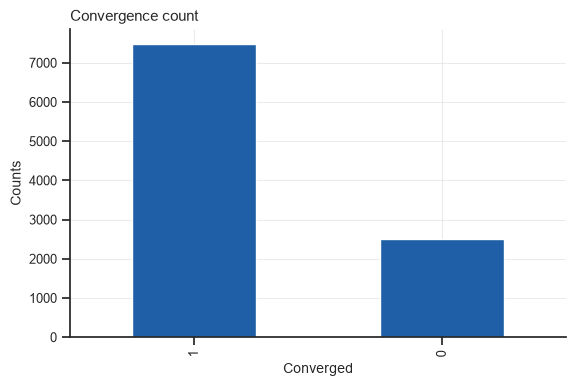

In [4]:
cv = df['converged'].value_counts().head(10).plot(kind = 'bar', title = 'Convergence count')

cv.set_xlabel('Converged')
cv.set_ylabel('Counts')
plt.show()

# Inspect the balance between converged and non-converged samples.

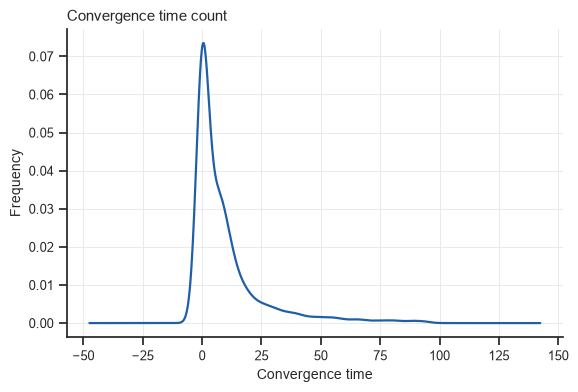

In [5]:
ct = df['convergence_time'].plot(kind = 'kde',
                title = 'Convergence time count')
ct.set_xlabel('Convergence time')
ct.set_ylabel('Frequency')
plt.show()

# Inspect the distribution of convergence times.

#### Added plots

ESC gives more energy than r = 0.5 in 74.7% of runs. Median gain: 1.21 (0.037% of the output); worst case: -2912.5.
Converged: 74.8% of runs; median convergence time 4.29 s.
Convergence time 0 s (r_hat starts at 0.5, already inside the 5 % band): 27.8% of runs.
Best ESC energy: 3293.9 = 99.63% of the ideal-density energy 3306.25.


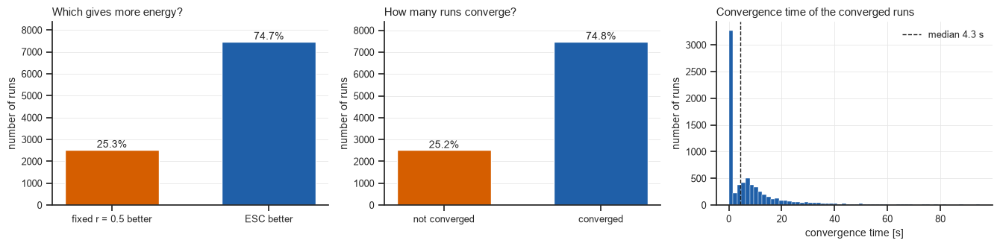

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4))
esc.outcome_bar(df['choose_ESC'], names=('fixed r = 0.5 better', 'ESC better'), title='Which gives more energy?', ax=axes[0])
esc.outcome_bar(df['converged'], names=('not converged', 'converged'), title='How many runs converge?', ax=axes[1])
esc.time_hist(df['convergence_time'], title='Convergence time of the converged runs', ax=axes[2])
fig.tight_layout()
plt.show()

gain = df['energy_ESC'] - df['energy_const']
print(f"ESC gives more energy than r = 0.5 in {df['choose_ESC'].mean():.1%} of runs. "
      f"Median gain: {gain.median():.2f} ({gain.median() / df['energy_const'].median():.3%} of the output); "
      f"worst case: {gain.min():.1f}.")
print(f"Converged: {df['converged'].mean():.1%} of runs; median convergence time {df['convergence_time'].median():.2f} s.")
print(f"Convergence time 0 s (r_hat starts at 0.5, already inside the 5 % band): {(df['convergence_time'] == 0).mean():.1%} of runs.")
print(f"Best ESC energy: {df['energy_ESC'].max():.1f} = {df['energy_ESC'].max() / esc.E_MAX:.2%} of the ideal-density energy {esc.E_MAX:.2f}.")

## 4. Parameter relationships

### Convergence time

#### Original plots

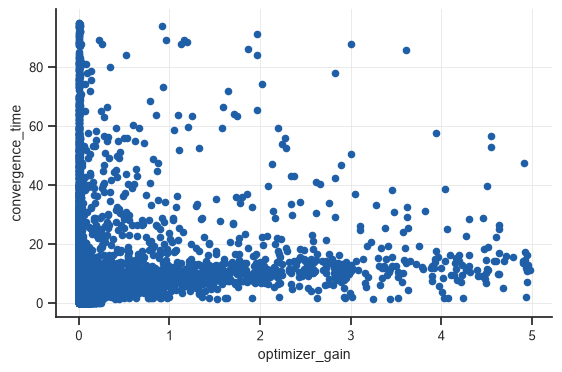

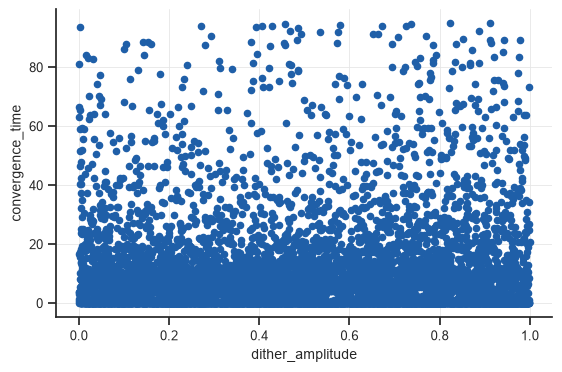

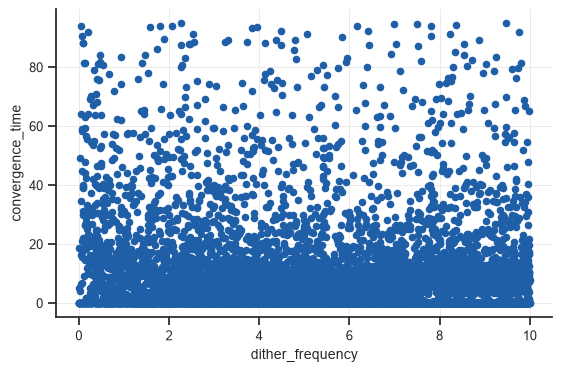

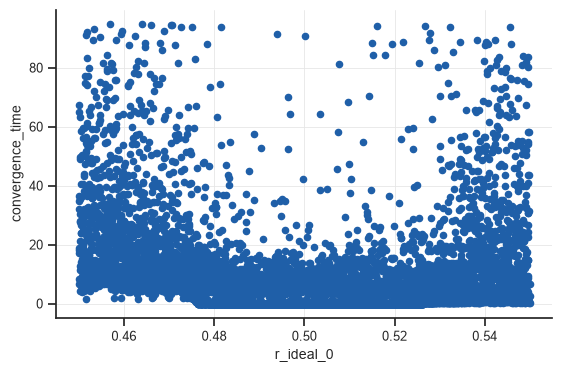

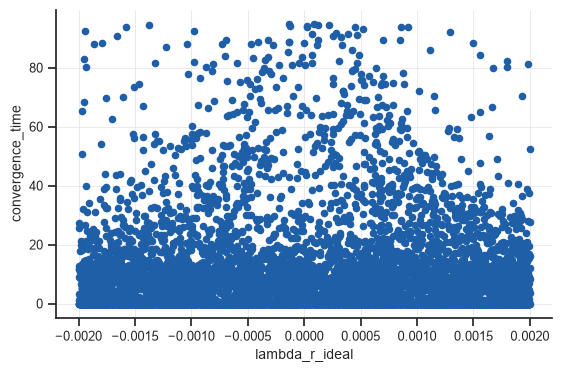

In [7]:
parameter_columns = ['optimizer_gain', 'dither_amplitude', 'dither_frequency', 'r_ideal_0', 'lambda_r_ideal']
for i in parameter_columns:
    df.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()

#### Added plots (one row, gain on a logarithmic axis, random sample)

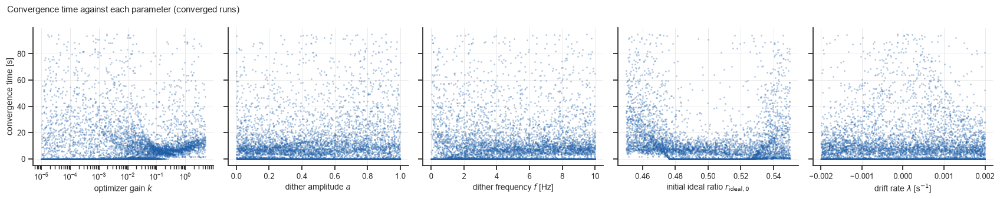

In [8]:
all_params = esc.ESC_PARAMS + esc.PLANT_PARAMS
esc.scatter_grid(df, all_params, 'convergence_time',
                 title='Convergence time against each parameter (converged runs)')
plt.show()

### Energy

ESC energy and fixed-ratio energy against each parameter: first over the full range, then zoomed in on the top
of the range. The dashed line is the energy at ideal densities.

#### Original plots

Compare methods and max energy: all runs, then energies above 3250, then above 3285.

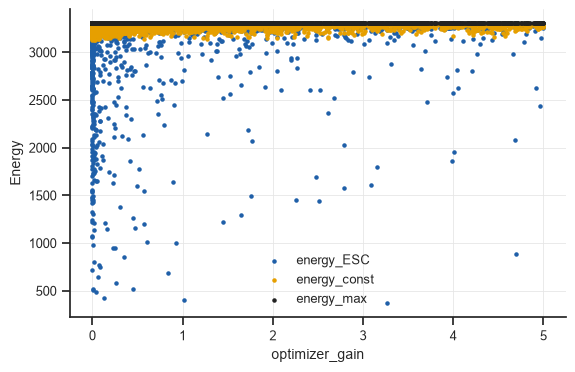

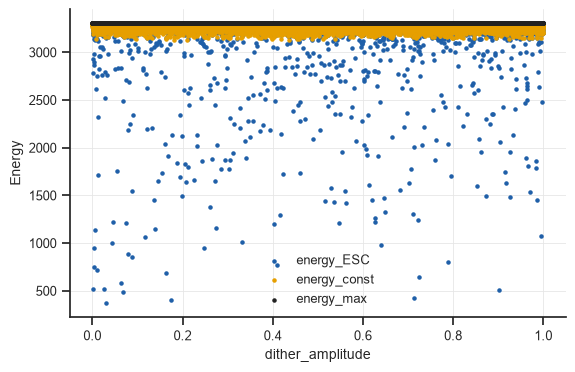

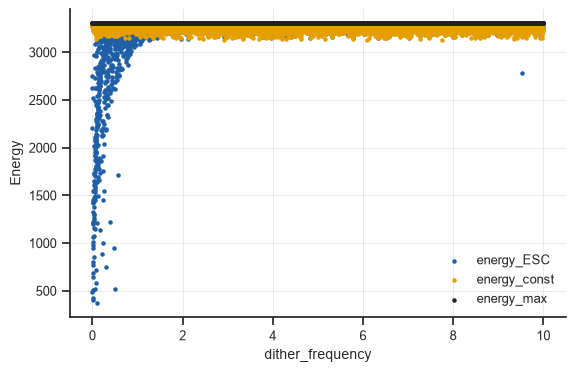

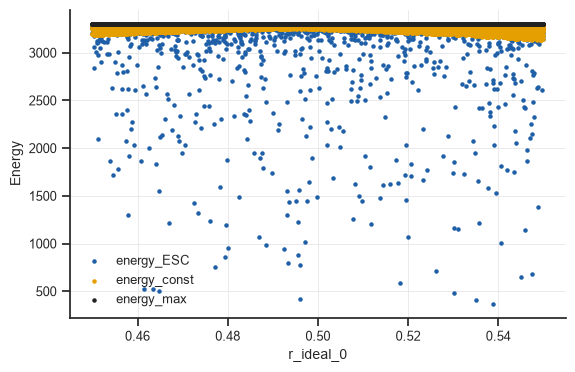

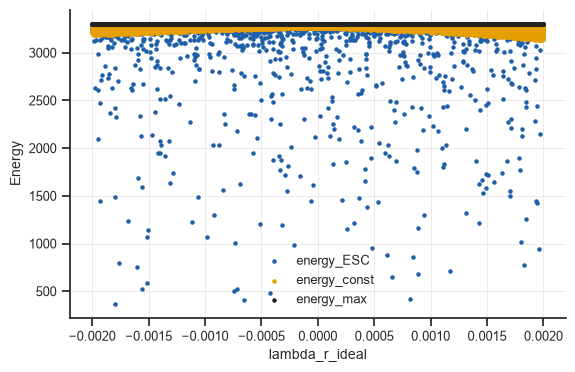

In [9]:
for i in parameter_columns:
    ax = df.plot(kind = 'scatter', x = i, y = 'energy_ESC', color = esc.COLORS['esc'], label = 'energy_ESC', s = 5)
    df.plot(kind = 'scatter', x = i, y = 'energy_const', color = esc.COLORS['fixed'], label = 'energy_const', s = 5, ax = ax)
    df.plot(kind = 'scatter', x = i, y = 'energy_max', color = esc.COLORS['ideal'], label = 'energy_max', s = 5, ax = ax)
    ax.set_ylabel('Energy')
    plt.show()

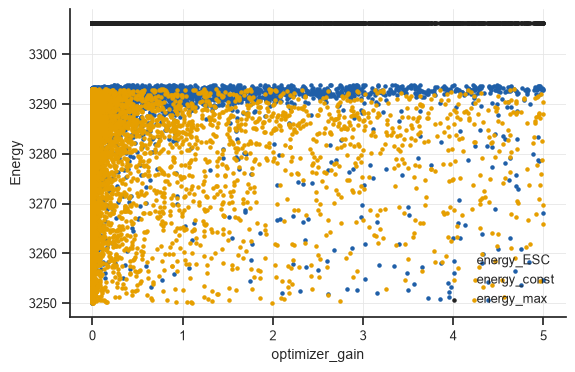

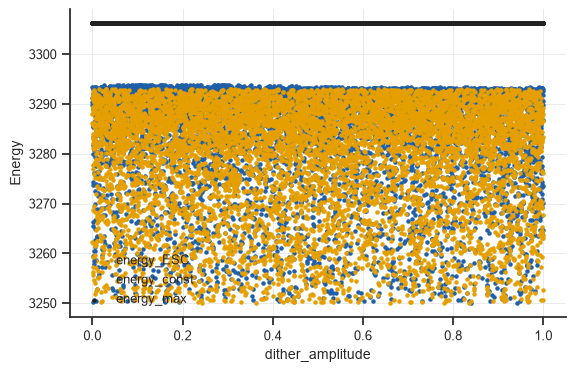

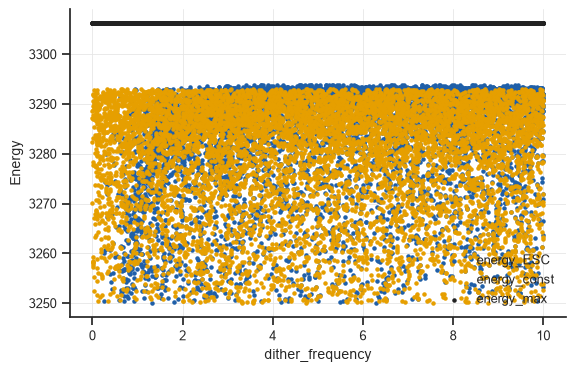

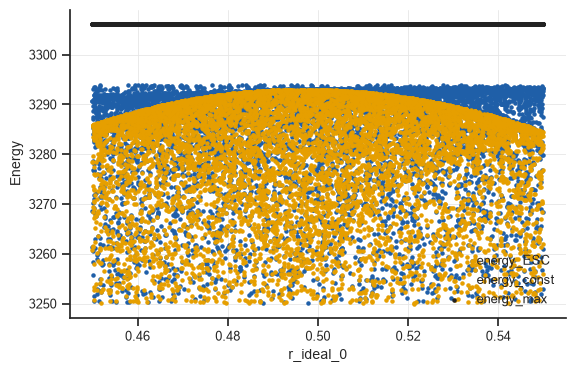

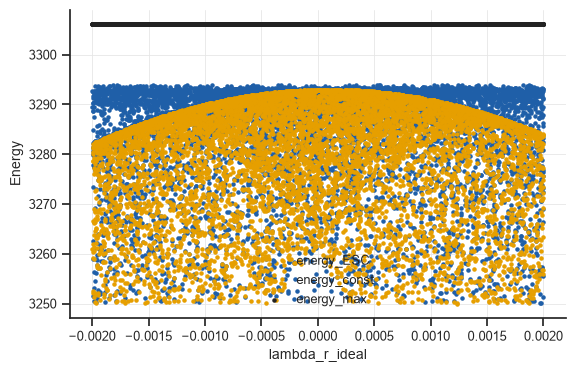

In [10]:
for i in parameter_columns:
    ax = df[df['energy_ESC'] > 3250].plot(kind = 'scatter', x = i, y = 'energy_ESC', color = esc.COLORS['esc'], label = 'energy_ESC', s = 5)
    df[df['energy_const'] > 3250].plot(kind = 'scatter', x = i, y = 'energy_const', color = esc.COLORS['fixed'], label = 'energy_const', s = 5, ax = ax)
    df[df['energy_max'] > 3250].plot(kind = 'scatter', x = i, y = 'energy_max', color = esc.COLORS['ideal'], label = 'energy_max', s = 5, ax = ax)
    ax.set_ylabel('Energy')
    plt.show()

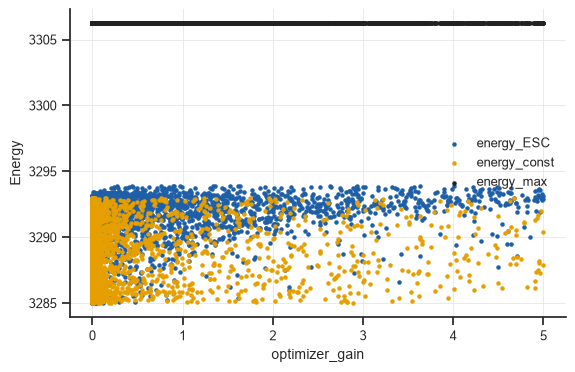

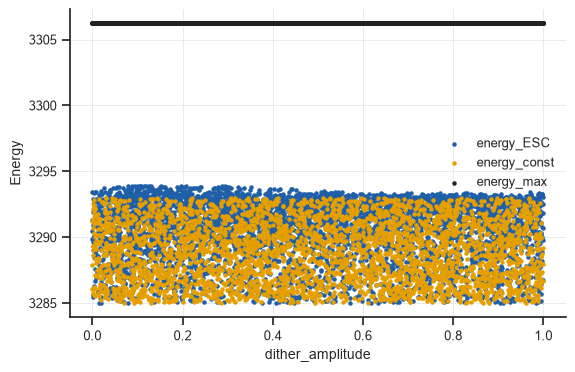

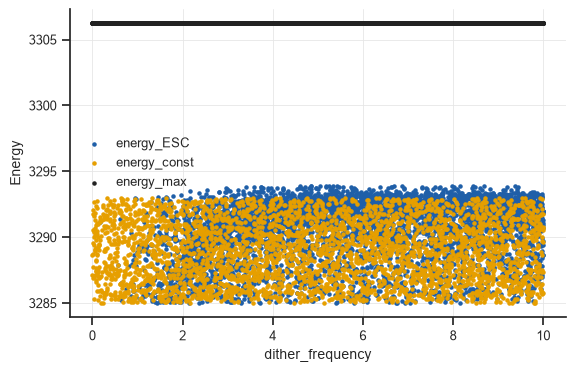

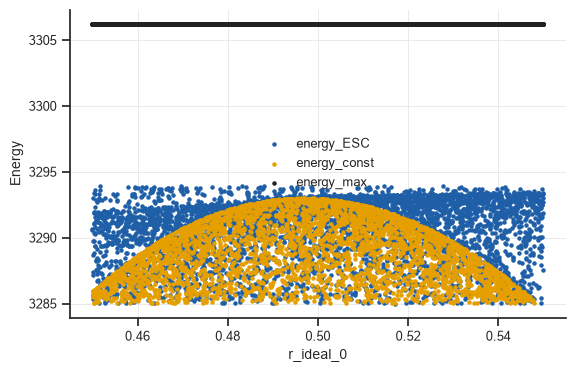

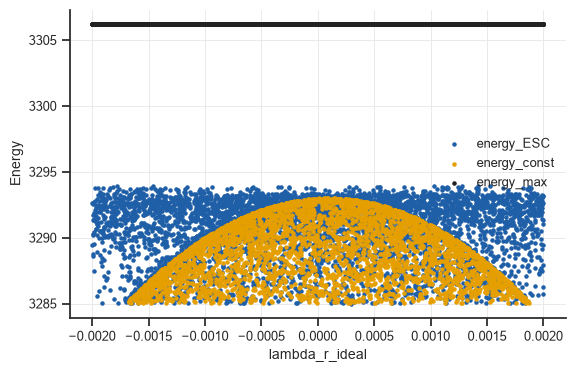

In [11]:
for i in parameter_columns:
    ax = df[df['energy_ESC'] > 3285].plot(kind = 'scatter', x = i, y = 'energy_ESC', color = esc.COLORS['esc'], label = 'energy_ESC', s = 5)
    df[df['energy_const'] > 3285].plot(kind = 'scatter', x = i, y = 'energy_const', color = esc.COLORS['fixed'], label = 'energy_const', s = 5, ax = ax)
    df[df['energy_max'] > 3285].plot(kind = 'scatter', x = i, y = 'energy_max', color = esc.COLORS['ideal'], label = 'energy_max', s = 5, ax = ax)
    ax.set_ylabel('Energy')
    plt.show()

Analyse ESC: energy with ESC only.

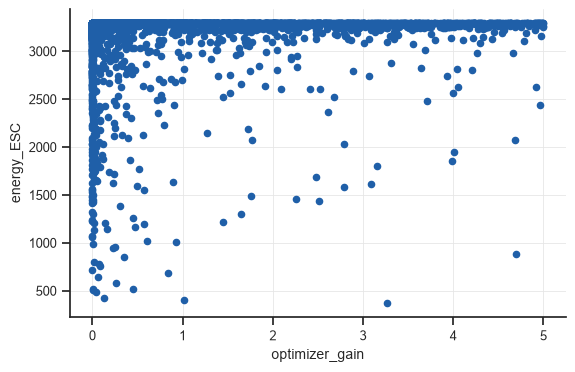

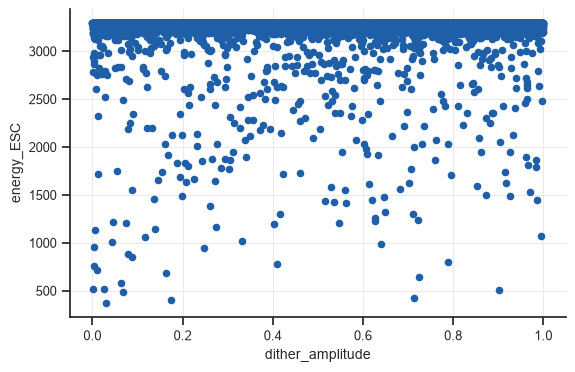

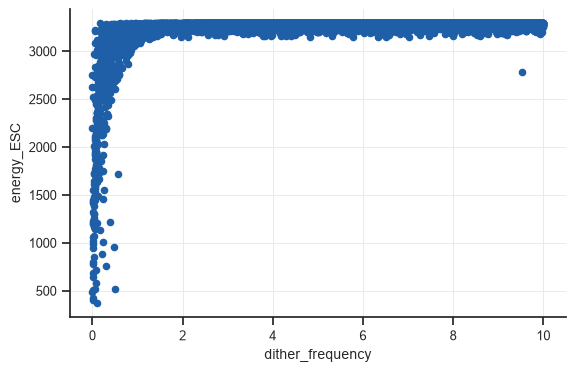

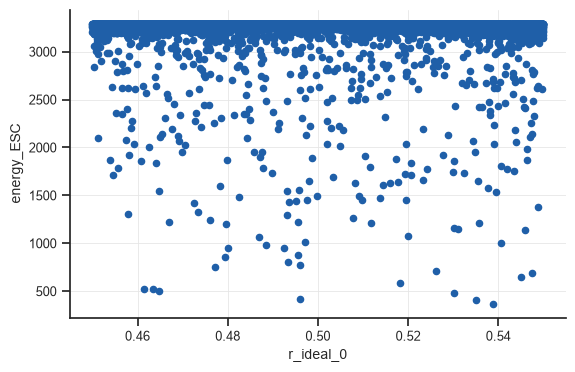

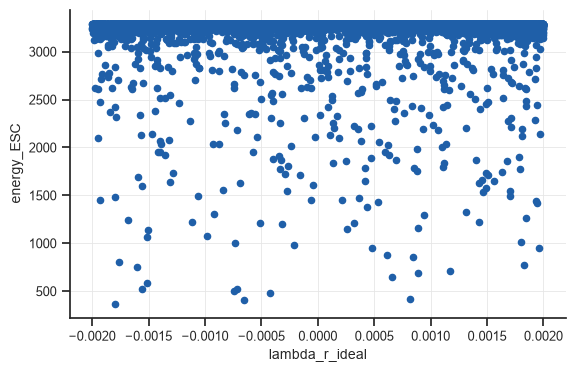

In [12]:
for i in parameter_columns:
    df.plot(kind = 'scatter',
            x = i,
            y = 'energy_ESC')
    plt.show()

#### Added plots (one row per zoom level)

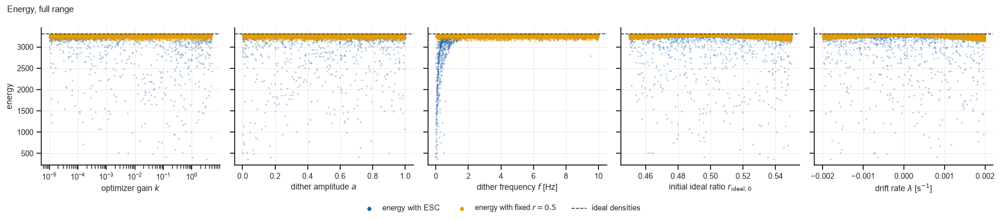

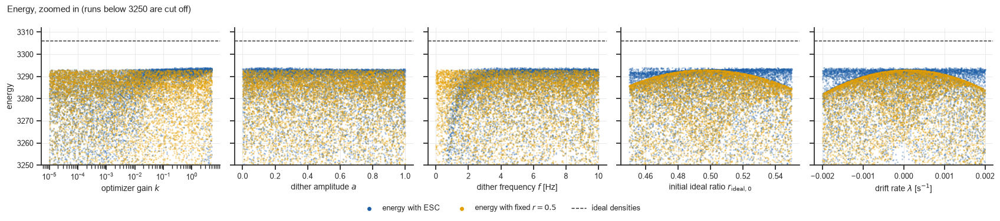

In [13]:
both = ['energy_ESC', 'energy_const']
esc.scatter_grid(df, all_params, both, hline=esc.E_MAX, hline_label='ideal densities', title='Energy, full range')
plt.show()
esc.scatter_grid(df, all_params, both, ylim=(3250, 3312), hline=esc.E_MAX, hline_label='ideal densities',
                 title='Energy, zoomed in (runs below 3250 are cut off)')
plt.show()

### Pair plot and correlations

#### Original plots

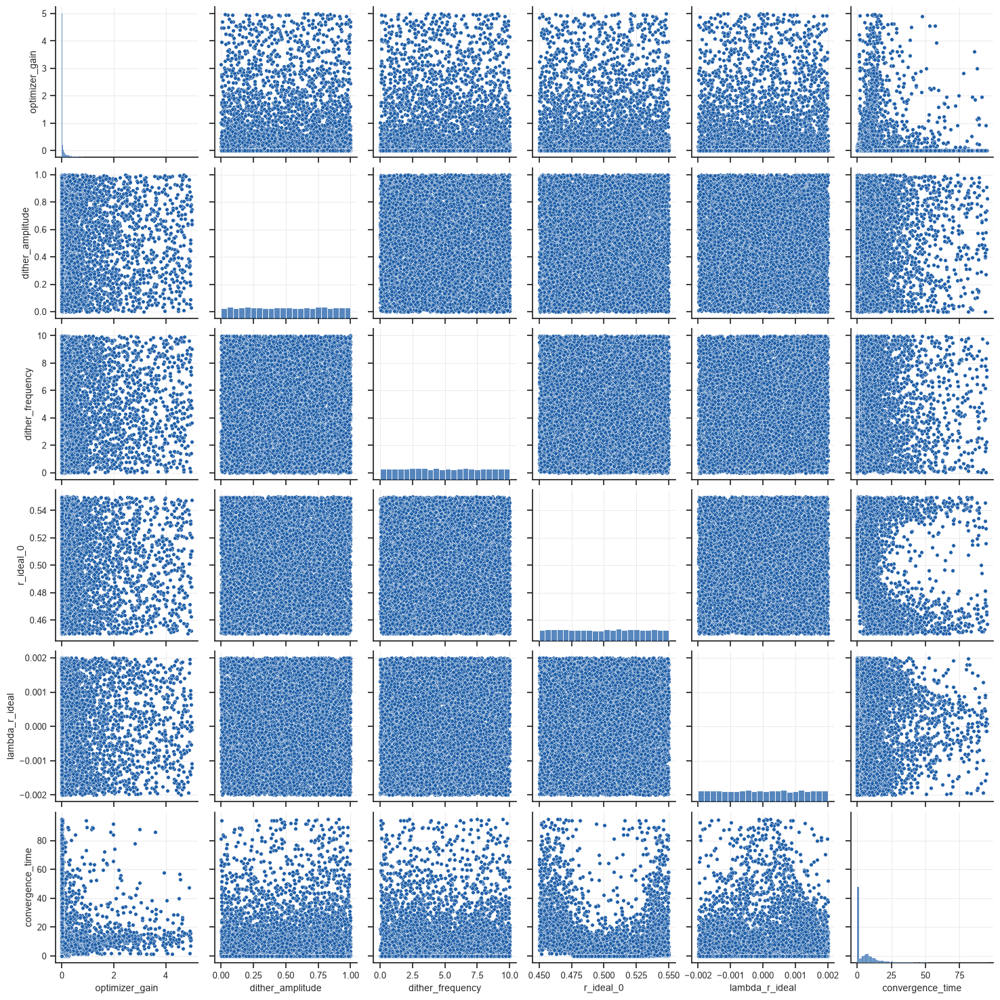

In [14]:
sns.pairplot(df,
             vars = parameter_columns + ['convergence_time'])
plt.show()

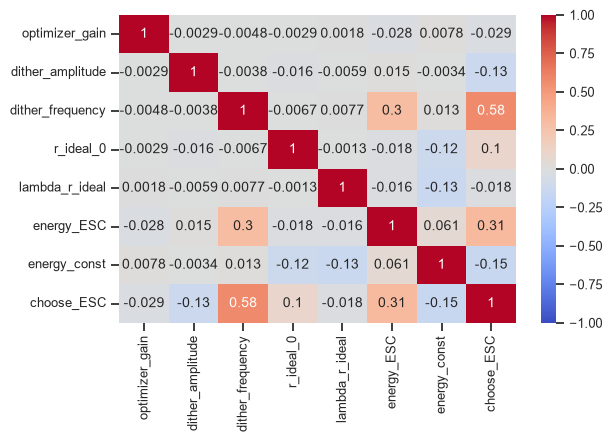

In [15]:
sns.heatmap(df.drop(columns = ['converged', 'convergence_time', 'energy_max']).corr(), annot = True, cmap = 'coolwarm', vmin = -1, vmax = 1, center = 0)
plt.show()

#### Added plots (gain on a logarithmic axis, random sample; heat map with the energy gain)

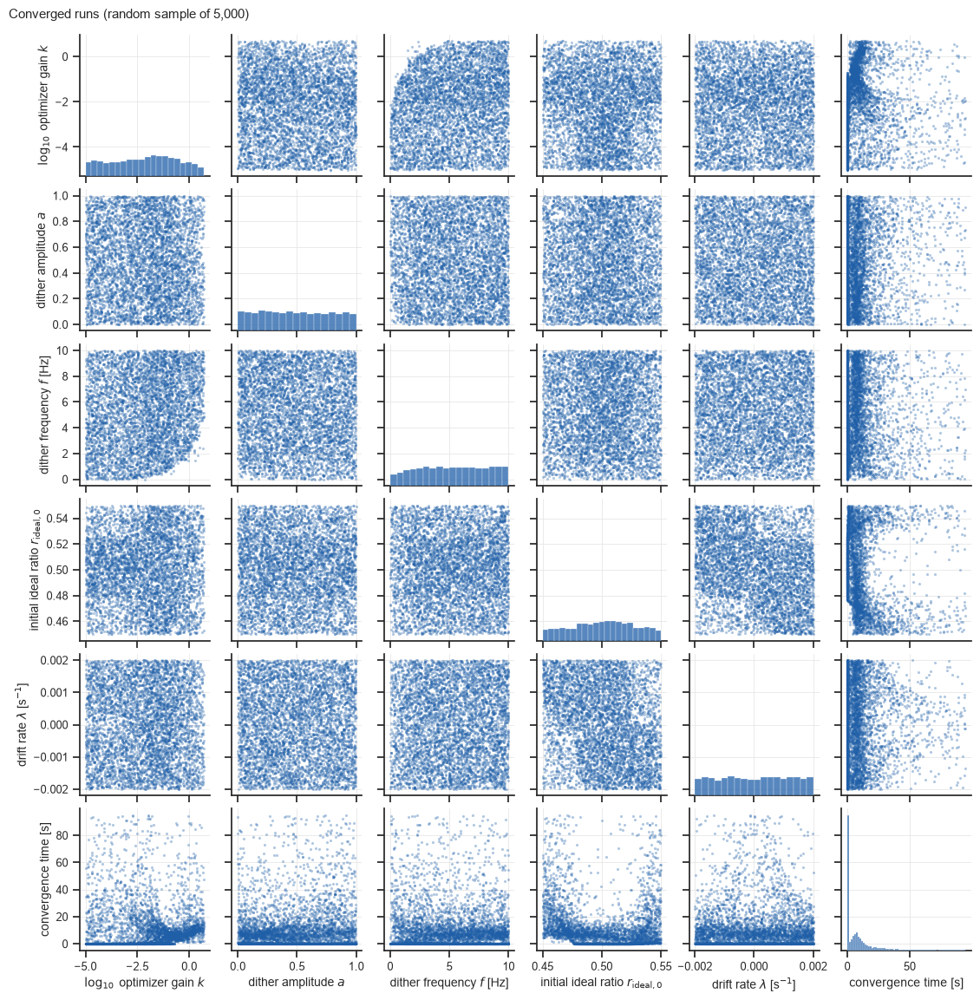

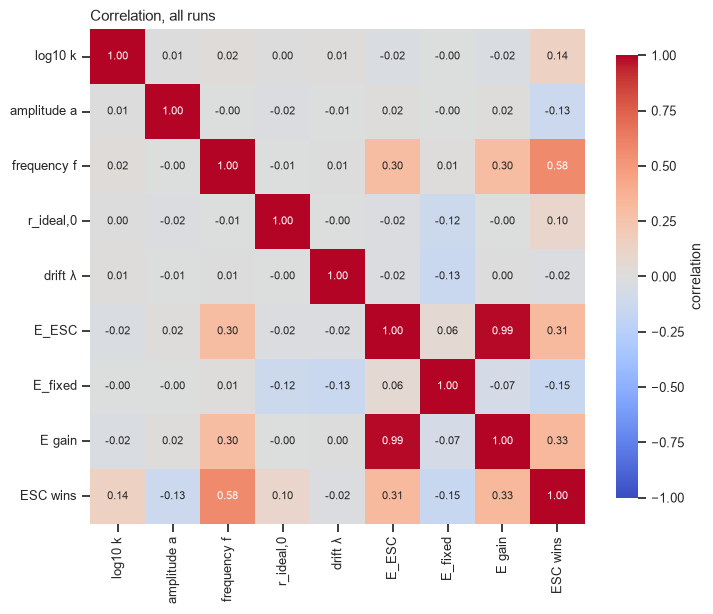

In [16]:
esc.pair_plot(df, all_params + ['convergence_time'], title='Converged runs (random sample of 5,000)')
plt.show()

d = esc.add_esc_quantities(df).assign(log10_gain=lambda t: np.log10(t['optimizer_gain']))
esc.corr_heatmap(d, ['log10_gain', 'dither_amplitude', 'dither_frequency', 'r_ideal_0', 'lambda_r_ideal',
                     'energy_ESC', 'energy_const', 'energy_gain', 'choose_ESC'], title='Correlation, all runs')
plt.show()

### Cut dataset: runs with a convergence time under 5 s

#### Original plots

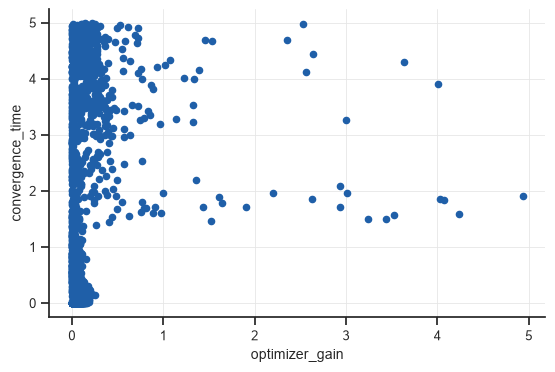

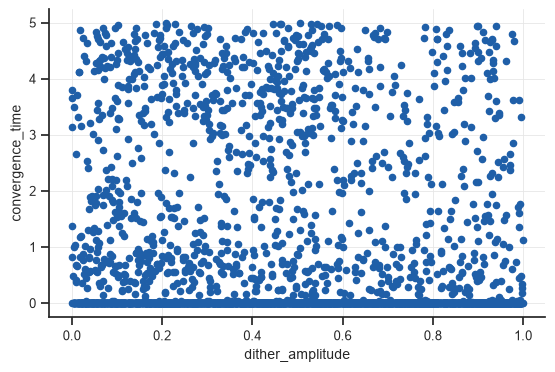

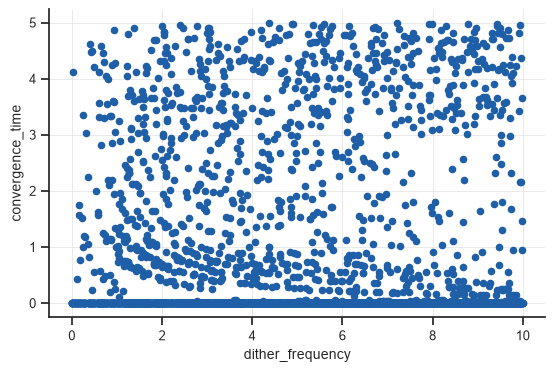

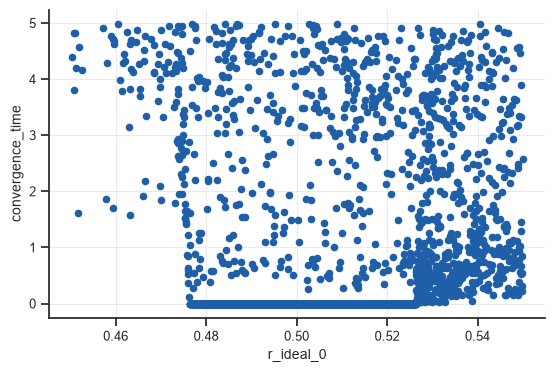

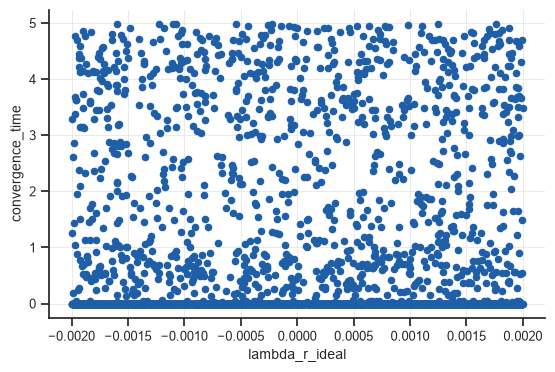

In [17]:
dfcut = df[df['convergence_time'] < 5]
for i in parameter_columns:
    dfcut.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()

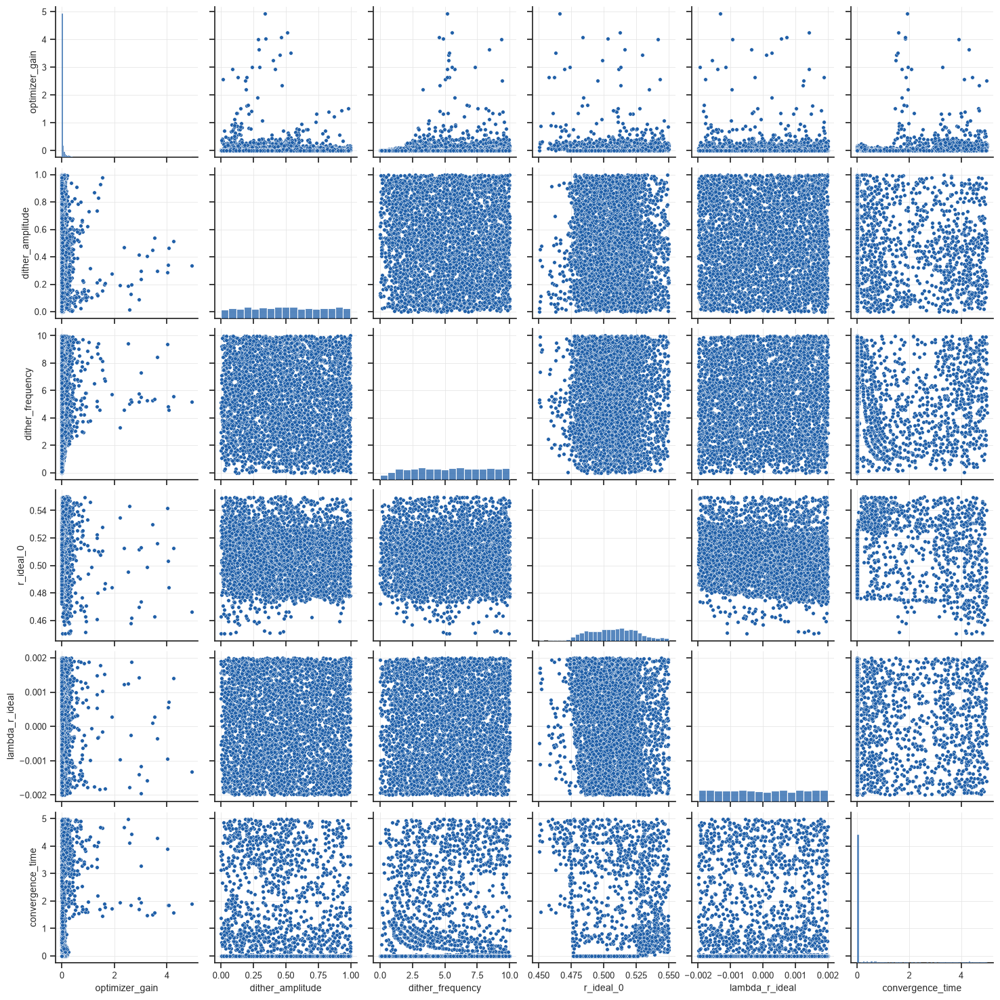

In [18]:
sns.pairplot(dfcut,
             vars = parameter_columns + ['convergence_time'])
plt.show()

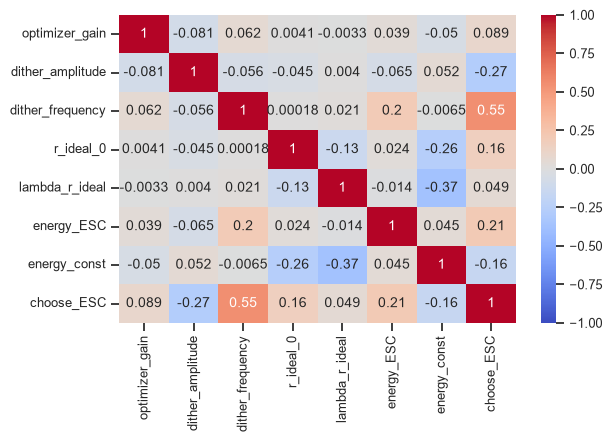

In [19]:
sns.heatmap(dfcut.drop(columns = ['converged', 'convergence_time', 'energy_max']).corr(), annot = True, cmap = 'coolwarm', vmin = -1, vmax = 1, center = 0)
plt.show()

## 5. Averaged-ESC analysis

Two numbers computed from the ESC parameters explain most of the energy outcome:

- the **averaged convergence rate** $\lambda_\mathrm{avg} = 2\,n_\mathrm{ref}^2\,k\,c(\omega)$ (`esc.lam_avg`): too small
  and the loop does nothing, too large and it becomes unstable;
- the **predicted dither loss** $L_\mathrm{dith} = T\,\frac{n_\mathrm{ref}^2}{4}\,\frac{2a^2\bar\alpha^2}{\bar\alpha^2+\omega^2}$
  (`esc.dither_loss`): the energy the dither oscillation itself costs over the run.

A run is called **well tuned** if $0.1 < \lambda_\mathrm{avg} < 3$ s$^{-1}$ and $L_\mathrm{dith} < 1$.
The derivation is in the report (Sections 3.2 and 3.3); it still has to be checked by the supervisor.

All runs: ESC wins in 74.7%.
Well-tuned runs: 1,523 (15.2% of the sweep); ESC wins in 93.3%, median gain 11.99.


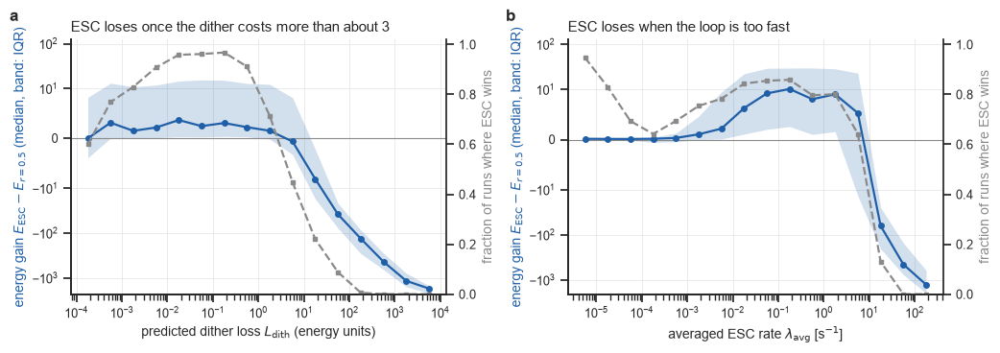

In [20]:
fig, d = esc.energy_vs_tuning(df)
plt.show()

tuned = d[esc.well_tuned(d)]
print(f"All runs: ESC wins in {d['choose_ESC'].mean():.1%}.")
print(f"Well-tuned runs: {len(tuned):,} ({len(tuned) / len(d):.1%} of the sweep); ESC wins in {tuned['choose_ESC'].mean():.1%}, "
      f"median gain {tuned['energy_gain'].median():.2f}.")

## 6. 3-D view

Interactive views in ESC-parameter space (drag to rotate); a random sample of the runs is drawn.

#### Original plots

In [21]:
import plotly.express as px

fig10k = px.scatter_3d(df,
                    x = 'optimizer_gain',
                    y = 'dither_amplitude',
                    z = 'dither_frequency',
                    color = 'convergence_time',
                    color_continuous_scale = 'Viridis',
                    title = '3D scatter',
                    labels = {'optimizer_gain' : 'Optimizer gain',
                              'dither_amplitude' : 'Dither amplitude',
                              'dither_frequency' : 'Dither Frequency'})
fig10k.update_traces(marker=dict(size=3))
fig10k.show()

# Exporting the plot (kept as a comment so the file is not rewritten every time the notebook runs)
# fig10k.write_html("3dscatter10k.html")

In [22]:
fig10k_E = px.scatter_3d(df,
                    x = 'optimizer_gain',
                    y = 'dither_amplitude',
                    z = 'dither_frequency',
                    color = 'energy_ESC',
                    color_continuous_scale = 'Viridis',
                    title = '3D scatter: ESC energy',
                    labels = {'optimizer_gain' : 'Optimizer gain',
                              'dither_amplitude' : 'Dither amplitude',
                              'dither_frequency' : 'Dither Frequency',
                              'energy_ESC' : 'ESC energy'})
fig10k_E.update_traces(marker=dict(size=3))
fig10k_E.show()

#### Added plots (does ESC beat the fixed ratio; gain on a logarithmic axis)

In [23]:
esc.scatter3d(df, 'choose_ESC', discrete=True, sample=10000, title='Does ESC beat the fixed ratio r = 0.5?').show()

## 7. Classifier: predict whether ESC beats the fixed ratio

Two small fully connected networks are trained to predict `choose_ESC` from the ESC and plant parameters plus
three engineered features. The data are split 60 % / 20 % / 20 % into training, cross-validation and test sets;
the test set is kept for the final model. The **majority baseline** is the accuracy of always predicting the
more frequent class.

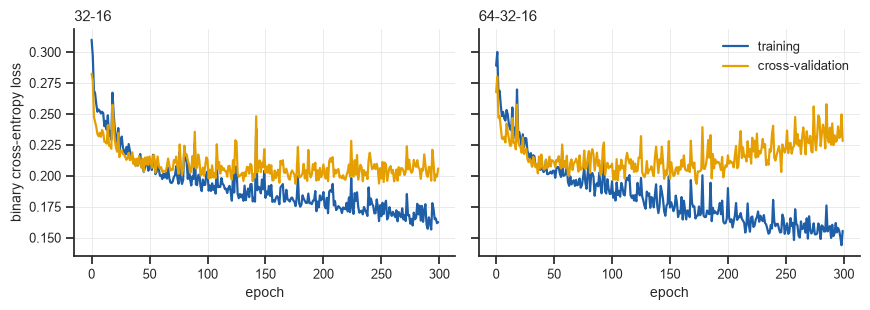

,train accuracy,CV accuracy,majority baseline (CV)
model,,,
32-16,0.928,0.916,0.752
64-32-16,0.925,0.909,0.752


In [24]:
import torch
import esc_ml as ml

features = df[all_params].copy()
features['log10gain'] = np.log10(df['optimizer_gain'])
features['sinfre'] = np.sin(df['dither_frequency'])
features['product'] = df['optimizer_gain'] * df['dither_amplitude'] * features['sinfre']
data = ml.split_data(features, df['choose_ESC'])

torch.manual_seed(1)   # reproducible initial weights
models = {'32-16': ml.make_model(features.shape[1], hidden=(32, 16)),
          '64-32-16': ml.make_model(features.shape[1], hidden=(64, 32, 16))}
histories = {name: ml.train_classifier(model, data['X_train'], data['y_train'], data['X_cv'], data['y_cv'],
                                       epochs=300, batch_size=100)
             for name, model in models.items()}

esc.loss_curves(histories)
plt.show()
ml.summary_table(models, data)

Confusion matrix of the better model, and where it goes wrong: the table gives the median of each feature for
the correct predictions, the false positives (predicted that ESC wins, it did not) and the false negatives.

In [25]:
best = max(models, key=lambda name: ml.accuracy(models[name], data['X_cv'], data['y_cv']))
ml.report(models[best], data['X_cv'], data['y_cv'], title=f'Model {best} on the cross-validation set')
ml.error_table(models[best], data['X_cv'], data['y_cv']).round(4)

Model 32-16 on the cross-validation set: accuracy 0.915 (majority baseline 0.752)
confusion matrix [rows: true 0/1, columns: predicted 0/1]
[[ 399   96]
 [  73 1432]]
              precision    recall  f1-score   support

           0      0.845     0.806     0.825       495
           1      0.937     0.951     0.944      1505

    accuracy                          0.915      2000
   macro avg      0.891     0.879     0.885      2000
weighted avg      0.914     0.915     0.915      2000



,correct,false negative,false positive
optimizer_gain,0.0084,0.0041,0.0161
dither_amplitude,0.5114,0.4591,0.4955
dither_frequency,5.3591,2.2754,3.2568
r_ideal_0,0.5035,0.4814,0.4943
lambda_r_ideal,0.0000,-0.0003,0.0002
log10gain,-2.0775,-2.3905,-1.7962
sinfre,0.2581,0.6645,0.4127
product,0.0000,0.0001,0.0001
number of runs,1831.0000,73.0000,96.0000


## Notes

- `choose_ESC` has no margin: an arbitrarily small energy difference counts as a win. Read it together with the
  size of the gain (Sections 3 and 5).
- Many runs "converge" at 0 s because $\hat r$ starts at 0.5, which is already inside the 5 % band for plants
  with $r_\mathrm{ideal}$ close to 0.5. For these runs the convergence time says nothing about the controller.
- `energy_max` cannot be reached. The best ESC energy printed in Section 3 is the practical ceiling.